In [1]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams['font.size'] = 12

In [2]:
import numpy as np 
import json
import os 
import h5py

from qiskit_aer import StatevectorSimulator

from symmer.operators.base import PauliwordOp, QuantumState

/Users/tom/Documents/ucl/projects/GAS/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import h5py

with h5py.File("LiH_data.h5", "r") as infile:

    f_op = PauliwordOp(infile["F_true_symp_matrix"][()],
                       infile["F_true_coeff_vec"][()])

    f_op_rounded = PauliwordOp(infile["F_rounded_symp_matrix"][()],
                                infile["F_rounded_coeff_vec"][()])
    
    linear_true = dict(zip(infile["lin_true_keys"][()],
                       infile["lin_true_values"][()]))
    
    quad_true = dict(zip( [(a,b) for a,b in infile["quad_true_keys"][()]],
                       infile["quad_true_values"][()]))
    

    linear_rounded = dict(zip(infile["lin_rounded_keys"][()],
                    infile["lin_rounded_values"][()]))
    
    quad_rounded   = dict(zip([(a,b) for a,b in infile["quad_rounded_keys"][()]],
                         infile["quad_rounded_values"][()]))
    
    n_elec = infile["SCF_nelec"][()]
    basis_set = infile["SCF_basis"][()]
    n_spin = 2*infile["h1e_MO"][()].shape[0]
    energy_soln = infile["SCF_e_tot"][()]


print("LOADED")

LOADED


In [4]:
### write QUBO problem!

from sympy import var
variables = [var(f'x{q_idx}', bool=True) for q_idx in range(n_spin)]

problem_fn = 0
for q_idx, coeff in linear_rounded.items():
    problem_fn+= variables[q_idx]*coeff

for (q_idx1, q_idx2), coeff in quad_rounded.items():
    problem_fn+= variables[q_idx1]*variables[q_idx2]*coeff

problem_fn

168.0*x0*x1 + 36.0*x0*x10 + 36.0*x0*x11 + 36.0*x0*x2 + 40.0*x0*x3 + 36.0*x0*x4 + 40.0*x0*x5 + 40.0*x0*x6 + 40.0*x0*x7 + 40.0*x0*x8 + 40.0*x0*x9 - 478.0*x0 + 36.0*x1*x10 + 36.0*x1*x11 + 40.0*x1*x2 + 36.0*x1*x3 + 40.0*x1*x4 + 36.0*x1*x5 + 40.0*x1*x6 + 40.0*x1*x7 + 40.0*x1*x8 + 40.0*x1*x9 - 478.0*x1 + 44.0*x10*x11 + 32.0*x10*x2 + 44.0*x10*x3 + 20.0*x10*x4 + 24.0*x10*x5 + 24.0*x10*x6 + 28.0*x10*x7 + 24.0*x10*x8 + 28.0*x10*x9 - 90.0*x10 + 44.0*x11*x2 + 32.0*x11*x3 + 24.0*x11*x4 + 20.0*x11*x5 + 28.0*x11*x6 + 24.0*x11*x7 + 28.0*x11*x8 + 24.0*x11*x9 - 90.0*x11 + 48.0*x2*x3 + 20.0*x2*x4 + 24.0*x2*x5 + 24.0*x2*x6 + 28.0*x2*x7 + 24.0*x2*x8 + 28.0*x2*x9 - 150.0*x2 + 24.0*x3*x4 + 20.0*x3*x5 + 28.0*x3*x6 + 24.0*x3*x7 + 28.0*x3*x8 + 24.0*x3*x9 - 150.0*x3 + 32.0*x4*x5 + 24.0*x4*x6 + 28.0*x4*x7 + 24.0*x4*x8 + 28.0*x4*x9 - 110.0*x4 + 28.0*x5*x6 + 24.0*x5*x7 + 28.0*x5*x8 + 24.0*x5*x9 - 110.0*x5 + 32.0*x6*x7 + 28.0*x6*x8 + 28.0*x6*x9 - 116.0*x6 + 28.0*x7*x8 + 28.0*x7*x9 - 116.0*x7 + 32.0*x8*x9 - 116.0*x8 

In [5]:
from itertools import combinations
def n_choose_k_vectors(n: int, k: int):
    return np.array(
        [
            [int(i in comb) for i in range(n)]
            for comb in combinations(np.arange(n), k)
        ]
    )

alph_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[0])
beta_bitstrings = n_choose_k_vectors(f_op.n_qubits//2, n_elec[1])

eigvals_counter = dict()
for alpha_term in alph_bitstrings:
    for beta_term in beta_bitstrings:
        state = np.vstack((alpha_term, beta_term)).T.reshape([f_op.n_qubits]) 
        evaluated = int(problem_fn.subs(zip(variables, state)))
        
        eigvals_counter[evaluated] = eigvals_counter.get(evaluated, 0) + 1

eigvals_counter, min(eigvals_counter.keys())

({-888: 1,
  -872: 2,
  -870: 4,
  -836: 2,
  -680: 2,
  -678: 4,
  -632: 2,
  -662: 8,
  -628: 2,
  -660: 6,
  -626: 4,
  -824: 1,
  -830: 4,
  -816: 2,
  -656: 6,
  -636: 2,
  -614: 4,
  -600: 8,
  -620: 6,
  -606: 4,
  -828: 2,
  -832: 2,
  -814: 4,
  -658: 4,
  -630: 4,
  -616: 4,
  -602: 8,
  -618: 4,
  -604: 4,
  -780: 1,
  -624: 2,
  -622: 4,
  -576: 2,
  -568: 2,
  -566: 4,
  -352: 3,
  -354: 4,
  -308: 2,
  -330: 8,
  -296: 6,
  -332: 6,
  -298: 8,
  -348: 2,
  -302: 4,
  -336: 4,
  -292: 4,
  -236: 4,
  -306: 4,
  -252: 2,
  -300: 2,
  -246: 4,
  -284: 2,
  -288: 3,
  -270: 8,
  -290: 4,
  -272: 6,
  -276: 4,
  -238: 4,
  -232: 2},
 -888)

In [6]:
target_psi = QuantumState(np.array([[0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1]])) # reverse order due to qiskit ordering

In [7]:
## load output states!
output_states_list_dicke = []
L_list = np.arange(0,11)
with h5py.File("LiH_output.h5", "r") as infile2:
    for idx in L_list:
        output_states_list_dicke.append(QuantumState(infile2[f"psi_{idx}_state_matrix"][()],
                                                infile2[f"psi_{idx}_coeff_vec"][()]))


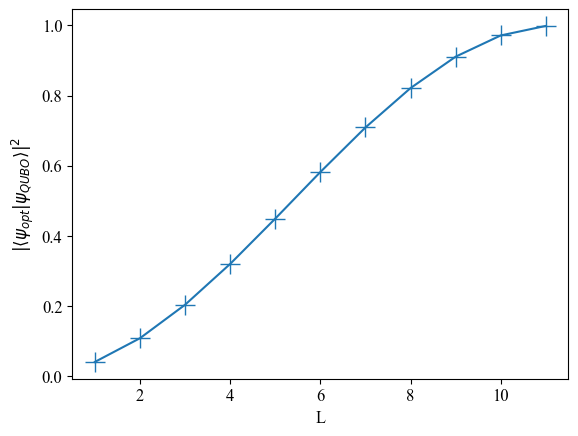

In [8]:
largest_amp_list_dicke = [np.abs(psi.state_op.coeff_vec[0])**2 for psi in output_states_list_dicke]
largest_bitstring_dicke = [psi[0] for psi in output_states_list_dicke]
overlap_dicke = [np.abs(target_psi.dagger * psi)**2 for psi in output_states_list_dicke]

plt.plot(L_list+1, overlap_dicke, marker="+", markersize=15)
plt.xlabel("L")
plt.ylabel(r"$|\langle \psi_{opt}| \psi_{QUBO} \rangle|^{2}$")
plt.savefig('LiH_dicke_L.png', dpi=300)
plt.show()

In [9]:
largest_bitstring_dicke

[ 0.199+0.000j |000000001111>,
  0.327+0.000j |000000001111>,
  0.450+0.000j |000000001111>,
  0.565+0.000j |000000001111>,
  0.670+0.000j |000000001111>,
  0.763+0.000j |000000001111>,
  0.842+0.000j |000000001111>,
  0.906+0.000j |000000001111>,
  0.954+0.000j |000000001111>,
  0.986+0.000j |000000001111>,
  0.999+0.000j |000000001111>]

In [10]:
state = QuantumState(largest_bitstring_dicke[-1].state_matrix[0,::-1]) # need to reverse as qiskit encocdes left to right

final_energy =f_op.expval(state)

print(f"The calculated energy is: {final_energy}, for the bitstring with probability: {np.abs(largest_bitstring_dicke[-1].state_op.coeff_vec)**2} to be measured")

The calculated energy is: (-7.8633576215351075+0j), for the bitstring with probability: [0.99868108] to be measured


In [11]:
print(f"error with the true answer is: {energy_soln-final_energy}")

error with the true answer is: (-5.329070518200751e-15+0j)
